# Project Handa — Exploratory Data Analysis & Modeling

This notebook walks through the data behind Project Handa's class-suspension
recommendation model for Olongapo City: the raw weather record, the
scraped suspension-announcement log, how the two are combined into a
labeled training set, and how the Random Forest model in
[`suspension_model.py`](./suspension_model.py) performs on it.

**Data sources**

| File | Contents |
|---|---|
| `Cubi Point Daily Data.csv` | Daily weather, 2022-01-01 to 2024-12-31 (rainfall, temperature, humidity, wind) for the Cubi Point station (Subic Bay area, adjacent to Olongapo) |
| `May-November Suspensions - Sheet1.csv` | Facebook-scraped class-suspension announcements, mostly Jul–Nov 2025, with the rainfall/forecast/time risk labels the mayor's office cited |

**A caveat worth stating up front:** the two files barely overlap in time —
weather data stops in 2024, and almost all scraped suspensions are from 2025.
Per the modeling assumption documented in `suspension_model.py`, every
2023–2024 date *not* listed in the suspension sheet is treated as a
true negative (no weather-related suspension that day). That assumption,
plus a small and heavily imbalanced positive class (~24 suspended days out
of ~730), means the metrics below are a rough benchmark for a thesis
proof-of-concept — not a production-grade evaluation. Later sections flag
where that shows up.


In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch

import suspension_model as sm

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 120)

# --- Validated palette (see dataviz skill's references/palette.md) ---------
COLOR = {
    "blue": "#2a78d6", "aqua": "#1baf7a", "yellow": "#eda100", "green": "#008300",
    "violet": "#4a3aa7", "red": "#e34948", "magenta": "#e87ba4", "orange": "#eb6834",
}
STATUS = {"good": "#0ca30c", "warning": "#fab219", "serious": "#ec835a", "critical": "#d03b3b"}
INK = {"primary": "#0b0b0b", "secondary": "#52514e", "muted": "#898781",
       "grid": "#e1e0d9", "baseline": "#c3c2b7"}
SURFACE = "#fcfcfb"
# Sequential blue ramp, light -> dark (steps 100/200/350/450/600/700)
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#5598e7", "#2a78d6", "#184f95", "#0d366b"]
DIVERGING = LinearSegmentedColormap.from_list("blue_red_div", ["#2a78d6", "#f0efec", "#e34948"])

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE,
    "savefig.facecolor": SURFACE,
    "axes.edgecolor": INK["baseline"], "axes.labelcolor": INK["secondary"],
    "grid.color": INK["grid"], "grid.linewidth": 0.8,
    "text.color": INK["primary"], "xtick.color": INK["muted"], "ytick.color": INK["muted"],
    "font.size": 11, "axes.spines.top": False, "axes.spines.right": False,
})

def style(ax, ygrid=True):
    if ygrid:
        ax.grid(axis="y", alpha=1)
        ax.set_axisbelow(True)
    return ax

RNG = 42


## 1. Weather data — load & overview

In [2]:
weather = sm.load_weather()
print(f"{len(weather)} daily records, {weather.DATE.min().date()} to {weather.DATE.max().date()}")
weather.head()


1096 daily records, 2022-01-01 to 2024-12-31


,YEAR,MONTH,DAY,RAINFALL,TMAX,TMIN,RH,WIND_SPEED,WIND_DIRECTION,DATE
0,2022,1,1,0.0,29.0,23.5,62,8,50,2022-01-01
1,2022,1,2,0.0,29.7,23.8,56,6,40,2022-01-02
2,2022,1,3,0.0,30.1,22.8,58,6,60,2022-01-03
3,2022,1,4,0.0,30.5,22.6,60,4,50,2022-01-04
4,2022,1,5,0.0,30.7,22.2,63,4,60,2022-01-05


In [3]:
weather.describe().round(2)


,YEAR,MONTH,DAY,RAINFALL,TMAX,TMIN,RH,WIND_SPEED,WIND_DIRECTION,DATE
count,1096.00,1096.00,1096.00,1096.00,1096.00,1096.00,1096.00,1096.00,1096.00,1096
mean,2023.00,6.52,15.73,9.38,32.38,24.47,74.45,3.47,116.33,2023-07-02 12:00:00
min,2022.00,1.00,1.00,0.00,25.90,19.20,52.00,1.00,6.00,2022-01-01 00:00:00
25%,2022.00,4.00,8.00,0.00,31.20,23.80,67.00,3.00,60.00,2022-10-01 18:00:00
50%,2023.00,7.00,16.00,0.00,32.30,24.60,75.00,3.00,80.00,2023-07-02 12:00:00
75%,2024.00,10.00,23.00,2.50,33.50,25.30,82.00,4.00,210.00,2024-04-01 06:00:00
max,2024.00,12.00,31.00,282.70,38.90,29.20,94.00,10.00,350.00,2024-12-31 00:00:00
std,0.82,3.45,8.81,28.24,2.08,1.24,9.49,1.15,78.20,NaN


No missing values are expected — `-1` in the raw `RAINFALL` column marks PAGASA's
"trace rainfall" convention (not a missing reading), and `load_weather()` clips it
to `0`. A quick check confirms nothing else is missing:


In [4]:
missing = weather.isna().sum()
missing.name = "missing_count"
missing.to_frame()


,missing_count
YEAR,0
MONTH,0
DAY,0
RAINFALL,0
TMAX,0
TMIN,0
RH,0
WIND_SPEED,0
WIND_DIRECTION,0
DATE,0


## 2. Rainfall and temperature over time

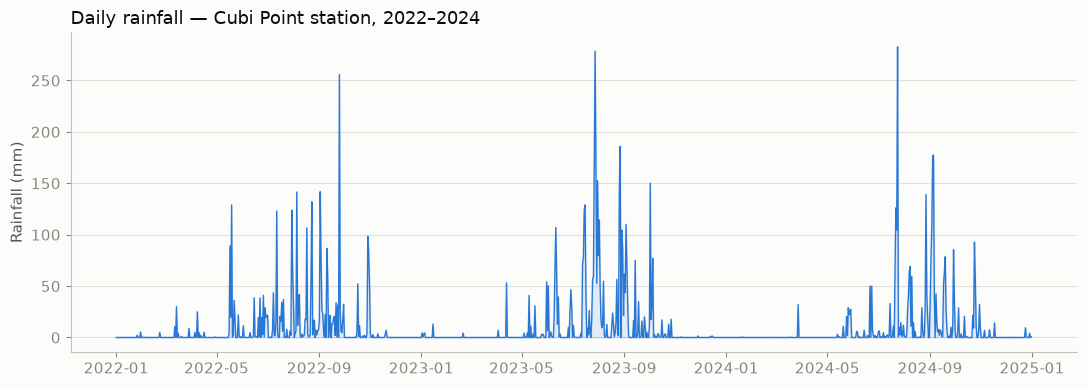

In [5]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weather.DATE, weather.RAINFALL, color=COLOR["blue"], linewidth=1)
ax.fill_between(weather.DATE, weather.RAINFALL, color=COLOR["blue"], alpha=0.12)
style(ax)
ax.set_title("Daily rainfall — Cubi Point station, 2022–2024", color=INK["primary"], loc="left", fontsize=13)
ax.set_ylabel("Rainfall (mm)")
fig.tight_layout()
plt.show()


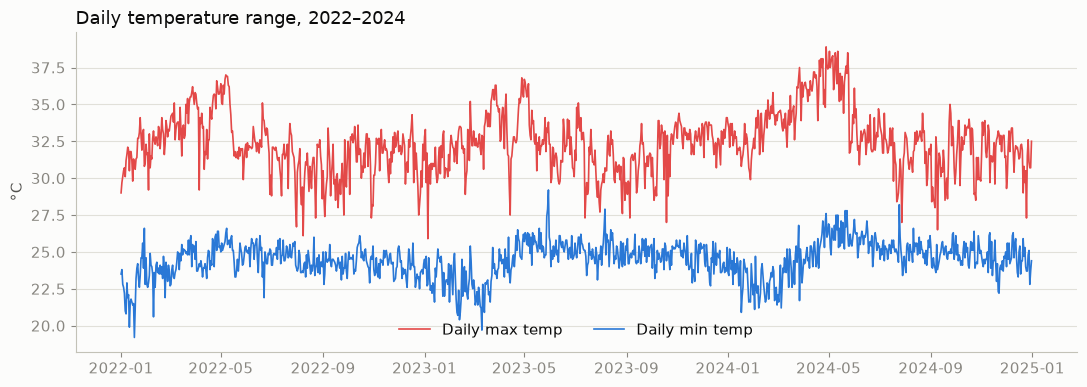

In [6]:
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(weather.DATE, weather.TMAX, color=COLOR["red"], linewidth=1.2, label="Daily max temp")
ax.plot(weather.DATE, weather.TMIN, color=COLOR["blue"], linewidth=1.2, label="Daily min temp")
style(ax)
ax.set_title("Daily temperature range, 2022–2024", color=INK["primary"], loc="left", fontsize=13)
ax.set_ylabel("°C")
ax.legend(frameon=False, loc="lower center", ncol=2)
fig.tight_layout()
plt.show()


Rainfall is strongly seasonal, as expected for the Philippines' habagat/amihan
pattern — a wet season roughly June–November with occasional very heavy days,
and a dry season December–May. Temperature is comparatively stable year-round
(a tropical station), which is part of why the model below leans on rainfall
and humidity rather than temperature to separate suspended from non-suspended
days.


## 3. Rainfall distribution & severity categories

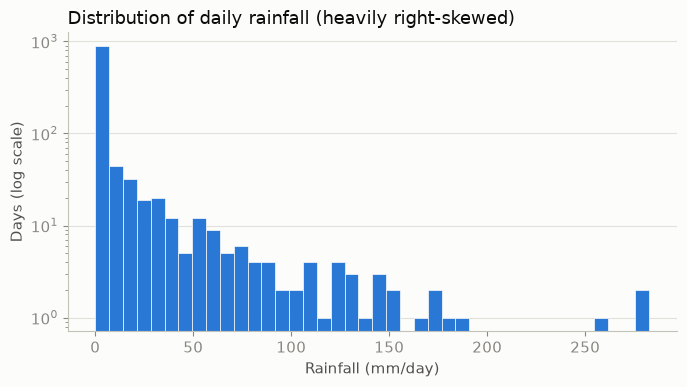

In [7]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(weather.RAINFALL, bins=40, color=COLOR["blue"], edgecolor=SURFACE, linewidth=0.5)
style(ax)
ax.set_yscale("log")
ax.set_xlabel("Rainfall (mm/day)")
ax.set_ylabel("Days (log scale)")
ax.set_title("Distribution of daily rainfall (heavily right-skewed)", color=INK["primary"], loc="left", fontsize=13)
fig.tight_layout()
plt.show()


`suspension_model.py` doesn't itself define a rainfall-severity bucketer
(that's in the earlier scratch file, `analysis.py`) — we import it directly
from there so the severity buckets match what was used for the initial manual
review of candidate high-rainfall days.


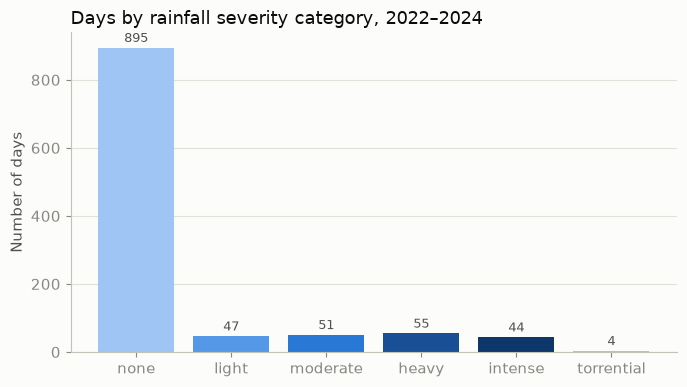

,days
RAIN_CATEGORY,
none,895
light,47
moderate,51
heavy,55
intense,44
torrential,4


In [8]:
import analysis as eda

order = ["none", "light", "moderate", "heavy", "intense", "torrential"]
weather["RAIN_CATEGORY"] = weather.RAINFALL.map(eda.rain_category)
counts = weather["RAIN_CATEGORY"].value_counts().reindex(order).fillna(0).astype(int)

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar(counts.index, counts.values, color=SEQ_BLUE[1:])
style(ax)
for rect, val in zip(bars, counts.values):
    ax.annotate(f"{val}", (rect.get_x() + rect.get_width() / 2, rect.get_height()),
                textcoords="offset points", xytext=(0, 4), ha="center",
                color=INK["secondary"], fontsize=9)
ax.set_title("Days by rainfall severity category, 2022–2024", color=INK["primary"], loc="left", fontsize=13)
ax.set_ylabel("Number of days")
fig.tight_layout()
plt.show()

counts.to_frame("days")


The overwhelming majority of days see no or light rain — "heavy" (≥30mm) or
worse days, the ones actually worth cross-checking against suspension
announcements, are a small minority. This is the class-imbalance problem in
miniature, before suspensions even enter the picture.


In [9]:
flagged = eda.flag_candidate_days(weather, min_mm=65)
print(f"{len(flagged)} days with >=65mm rainfall (intense/torrential territory):")
flagged


48 days with >=65mm rainfall (intense/torrential territory):


,DATE,RAINFALL,TMAX,TMIN,RH,WIND_SPEED,CATEGORY
0,2024-07-24,282.7,29.0,24.3,90,8,torrential
1,2023-07-28,278.5,28.7,23.1,93,5,torrential
2,2022-09-25,255.8,29.4,23.5,85,3,torrential
3,2023-08-27,185.9,27.6,24.0,92,3,torrential
4,2024-09-05,177.4,28.4,24.1,94,6,intense
5,2024-09-04,176.6,28.6,24.6,92,6,intense
6,2023-07-29,170.5,29.8,24.2,91,4,intense
7,2023-07-27,168.0,29.3,24.9,87,10,intense
8,2023-07-31,152.5,27.7,24.5,92,3,intense
9,2023-10-02,150.2,31.4,23.9,86,3,intense


## 4. Suspension announcements (scraped log)

In [10]:
suspensions = sm.load_suspensions()
print(f"{len(suspensions)} unique suspension-decision dates, "
      f"{suspensions.Date.min().date()} to {suspensions.Date.max().date()}")
suspensions.head(10)


43 unique suspension-decision dates, 2023-06-13 to 2025-11-11


,Date,Date Posted,Time Posted,Rainfall Level,Forecast Risk,Time Risk,Suspension Decision,Pre-School,Elementary,High School,College
0,2023-06-13,NaN,6:54,Yellow Rainfall Warning,Moderate Risk,Whole day,1,1.0,1.0,1.0,0.0
1,2023-07-26,NaN,5:43 AM,NaN,High Risk,Whole day,1,NaN,NaN,NaN,NaN
2,2023-07-28,NaN,NaN,NaN,High Risk,Whole day,1,NaN,NaN,NaN,NaN
3,2023-07-29,NaN,6:40 PM,NaN,High Risk,Whole day,1,NaN,NaN,NaN,NaN
4,2023-07-31,NaN,5:43 AM,NaN,High Risk,Whole Day,1,NaN,NaN,NaN,NaN
5,2023-08-30,NaN,11:42 AM,NaN,High Risk,Afternoon Suspension,1,1.0,1.0,1.0,1.0
6,2023-08-31,NaN,5:57 AM,NaN,High Risk,Whole Day,1,1.0,1.0,1.0,1.0
7,2023-09-01,NaN,5:58 AM,NaN,High Risk,Whole Day,1,1.0,1.0,1.0,1.0
8,2023-09-02,NaN,5:58 AM,NaN,High Risk,Whole Day,1,1.0,1.0,1.0,1.0
9,2023-09-03,NaN,5:59 AM,NaN,High Risk,Whole Day,1,1.0,1.0,1.0,1.0


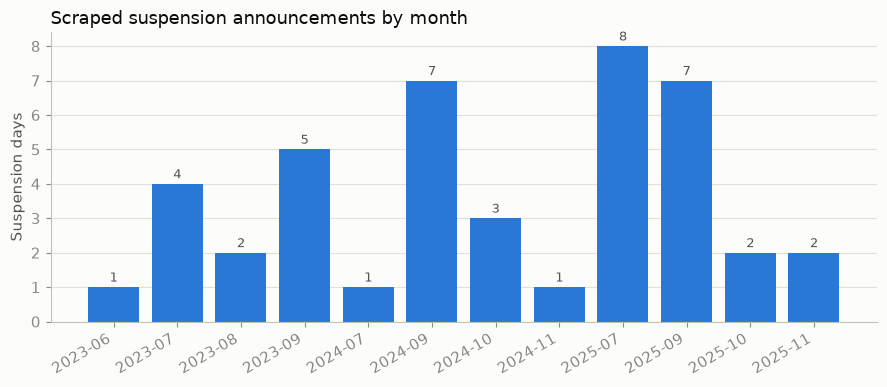

In [11]:
by_month = (
    suspensions.assign(YEAR_MONTH=suspensions.Date.dt.to_period("M"))
    .groupby("YEAR_MONTH").size()
)

fig, ax = plt.subplots(figsize=(9, 4))
labels = [str(p) for p in by_month.index]
bars = ax.bar(labels, by_month.values, color=COLOR["blue"])
style(ax)
for rect, val in zip(bars, by_month.values):
    ax.annotate(f"{val}", (rect.get_x() + rect.get_width() / 2, rect.get_height()),
                textcoords="offset points", xytext=(0, 4), ha="center",
                color=INK["secondary"], fontsize=9)
ax.set_title("Scraped suspension announcements by month", color=INK["primary"], loc="left", fontsize=13)
ax.set_ylabel("Suspension days")
plt.setp(ax.get_xticklabels(), rotation=30, ha="right")
fig.tight_layout()
plt.show()


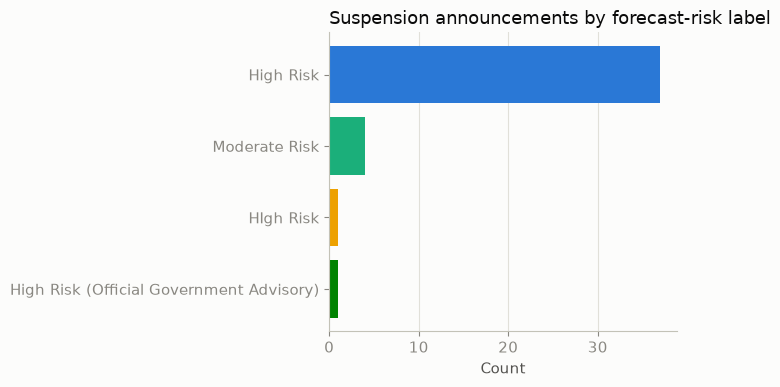

In [12]:
risk_counts = suspensions["Forecast Risk"].value_counts()

fig, ax = plt.subplots(figsize=(7, 4))
palette = list(COLOR.values())
bars = ax.barh(risk_counts.index[::-1], risk_counts.values[::-1], color=palette[:len(risk_counts)][::-1])
style(ax, ygrid=False)
ax.grid(axis="x", alpha=1)
ax.set_axisbelow(True)
ax.set_title("Suspension announcements by forecast-risk label", color=INK["primary"], loc="left", fontsize=13)
ax.set_xlabel("Count")
fig.tight_layout()
plt.show()


Every row in this sheet is a day a suspension **was** declared — there's no
explicit "no suspension" record, which is exactly why `build_labeled_dataset`
below has to construct negatives from the weather calendar instead.


## 5. Building the labeled training set

Following the assumption documented in `suspension_model.py`: every date in
`weather` between 2023-01-01 and 2024-12-31 that does **not** appear in the
suspension sheet is labeled `SUSPENDED = 0`; every scraped date in that window
is labeled `SUSPENDED = 1`. 2022 is excluded, and any 2025 suspension dates
fall outside the weather data's range and are dropped (shown below).


In [13]:
dataset, coverage_start, coverage_end, dropped = sm.build_labeled_dataset(
    weather, suspensions, start="2023-01-01", end="2024-12-31"
)
features = sm.build_features(dataset)

print(f"Usable window: {coverage_start.date()} to {coverage_end.date()}")
print(f"Total days: {len(features)}  |  Suspended: {features.SUSPENDED.sum()} "
      f"({features.SUSPENDED.mean():.1%})")
print(f"Scraped suspension dates dropped (outside window): {len(dropped)}")
dropped[["Date", "Rainfall Level", "Forecast Risk"]]


Usable window: 2023-01-01 to 2024-12-31
Total days: 731  |  Suspended: 24 (3.3%)
Scraped suspension dates dropped (outside window): 19


,Date,Rainfall Level,Forecast Risk
24,2025-07-03,Heavy Rain,High Risk
25,2025-07-18,Yellow Warning,Moderate Risk
26,2025-07-19,Heavy Rain,High Risk
27,2025-07-21,Heavy Rain,High Risk
28,2025-07-22,Heavy Rain,High Risk
29,2025-07-23,Heavy Rain,High Risk
30,2025-07-24,Heavy Rain,High Risk
31,2025-07-25,DILG + PAGASA Advisory Heavy Weather,High Risk (Official Government Advisory)
32,2025-09-05,Yellow Heavy Rainfall Warning + High Tide Risk,High Risk
33,2025-09-06,Yellow Heavy Rainfall Warning,High Risk


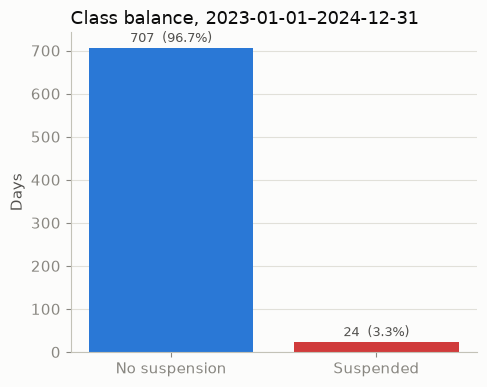

In [14]:
class_counts = features.SUSPENDED.value_counts().rename({0: "No suspension", 1: "Suspended"})

fig, ax = plt.subplots(figsize=(5, 4))
bars = ax.bar(class_counts.index, class_counts.values,
              color=[COLOR["blue"], STATUS["critical"]])
style(ax)
for rect, val in zip(bars, class_counts.values):
    ax.annotate(f"{val}  ({val/len(features):.1%})",
                (rect.get_x() + rect.get_width() / 2, rect.get_height()),
                textcoords="offset points", xytext=(0, 4), ha="center",
                color=INK["secondary"], fontsize=9)
ax.set_title(f"Class balance, {coverage_start.date()}–{coverage_end.date()}",
             color=INK["primary"], loc="left", fontsize=13)
ax.set_ylabel("Days")
fig.tight_layout()
plt.show()


A roughly 97/3 split. This is the central limitation of the current dataset —
every metric from here on should be read with that imbalance in mind (a model
that always predicts "no suspension" would already score ~97% accuracy while
being useless).


In [15]:
features[["DATE", "RAINFALL", "RAIN_3DAY_SUM", "RAIN_7DAY_SUM", "TMAX", "TMIN", "RH", "WIND_SPEED", "SUSPENDED"]].sample(8, random_state=RNG).sort_values("DATE")


,DATE,RAINFALL,RAIN_3DAY_SUM,RAIN_7DAY_SUM,TMAX,TMIN,RH,WIND_SPEED,SUSPENDED
33,2023-02-03,0.0,0.0,0.0,32.4,23.1,64,4,0
39,2023-02-09,0.0,0.0,0.0,31.0,20.9,60,4,0
300,2023-10-28,0.0,17.7,30.7,33.0,25.3,75,3,0
356,2023-12-23,0.0,0.0,0.0,30.9,23.6,64,5,0
456,2024-04-01,0.0,0.0,32.0,36.2,24.5,66,3,0
557,2024-07-11,2.0,2.5,7.4,31.7,24.5,84,2,0
633,2024-09-25,0.0,1.4,116.1,34.4,25.2,78,3,0
703,2024-12-04,0.0,0.0,0.0,33.2,25.6,80,2,0


## 6. How suspended days differ from ordinary days

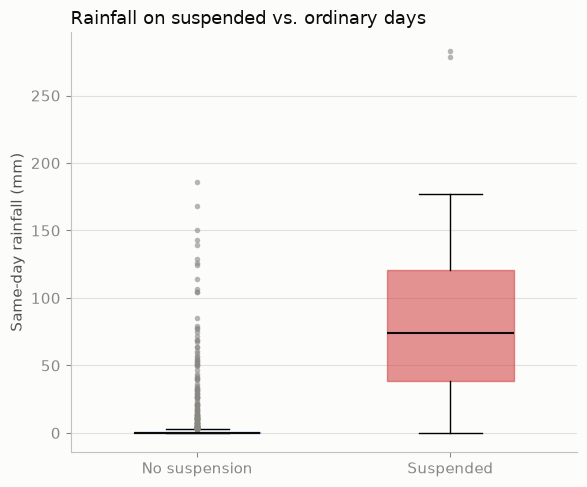

In [16]:
fig, ax = plt.subplots(figsize=(6, 5))
groups = [features.loc[features.SUSPENDED == 0, "RAINFALL"], features.loc[features.SUSPENDED == 1, "RAINFALL"]]
bp = ax.boxplot(groups, tick_labels=["No suspension", "Suspended"], patch_artist=True, widths=0.5,
                 medianprops=dict(color=INK["primary"], linewidth=1.5),
                 flierprops=dict(markerfacecolor=INK["muted"], markeredgecolor="none", markersize=4, alpha=0.6))
for patch, c in zip(bp["boxes"], [COLOR["blue"], STATUS["critical"]]):
    patch.set_facecolor(c)
    patch.set_alpha(0.55)
    patch.set_edgecolor(c)
style(ax)
ax.set_ylabel("Same-day rainfall (mm)")
ax.set_title("Rainfall on suspended vs. ordinary days", color=INK["primary"], loc="left", fontsize=13)
fig.tight_layout()
plt.show()


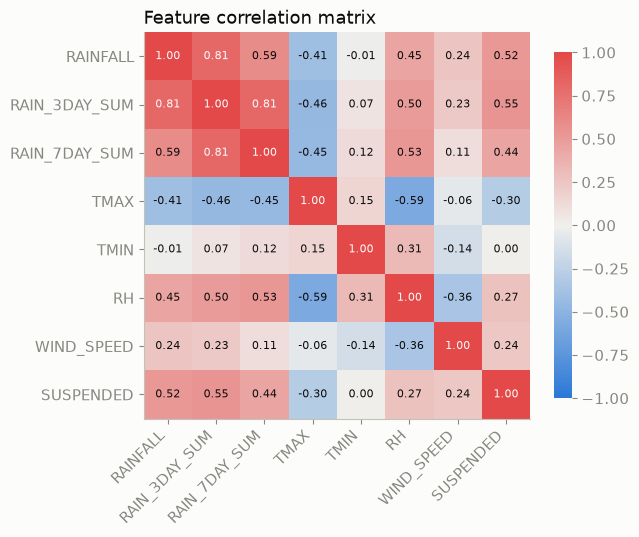

In [17]:
corr_cols = ["RAINFALL", "RAIN_3DAY_SUM", "RAIN_7DAY_SUM", "TMAX", "TMIN", "RH", "WIND_SPEED", "SUSPENDED"]
corr = features[corr_cols].corr()

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(corr.values, cmap=DIVERGING, vmin=-1, vmax=1)
ax.set_xticks(range(len(corr_cols)), corr_cols, rotation=45, ha="right")
ax.set_yticks(range(len(corr_cols)), corr_cols)
for i in range(len(corr_cols)):
    for j in range(len(corr_cols)):
        v = corr.values[i, j]
        ax.text(j, i, f"{v:.2f}", ha="center", va="center",
                color=INK["primary"] if abs(v) < 0.6 else SURFACE, fontsize=8)
cbar = fig.colorbar(im, ax=ax, shrink=0.85)
cbar.outline.set_visible(False)
ax.set_title("Feature correlation matrix", color=INK["primary"], loc="left", fontsize=13)
fig.tight_layout()
plt.show()


`RAINFALL`, `RAIN_3DAY_SUM`, and `RAIN_7DAY_SUM` are (unsurprisingly) the
features most correlated with `SUSPENDED`, and highly correlated with each
other — the model treats them as related-but-distinct signals of "how wet has
it been," which the feature-importance chart later confirms.


## 7. Model training — Random Forest (regularized)

This is the model actually served by the API (`app/ml_model.py`):
`max_depth=4, min_samples_leaf=4`, chosen because leave-one-out CV showed it
generalizes better than an unconstrained Random Forest, Gradient Boosting, or
Logistic Regression on this small dataset (see §9 below).

It is first trained on a stratified 75:25 split (548 training days, 183 test
days) to get a held-out confusion matrix. The unconstrained Random Forest
(`sm.train_random_forest`) is not used here; it appears alongside the other
candidates in §8–§9.

In [18]:
from sklearn.metrics import accuracy_score, confusion_matrix, f1_score, precision_score, recall_score
from sklearn.model_selection import train_test_split

SERVED = "Random Forest (regularized)"
reg_rf = sm.REGULARIZED_MODEL_FACTORIES[SERVED]
F = sm.FEATURE_COLS

X_train, X_test, y_train, y_test = train_test_split(
    features[F], features.SUSPENDED, test_size=0.25, random_state=42, stratify=features.SUSPENDED
)
model = reg_rf(random_state=42).fit(X_train, y_train)
y_pred = model.predict(X_test)

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "precision": precision_score(y_test, y_pred, zero_division=0),
    "recall": recall_score(y_test, y_pred, zero_division=0),
    "f1": f1_score(y_test, y_pred, zero_division=0),
    "confusion_matrix": confusion_matrix(y_test, y_pred),
}
metrics_table = pd.DataFrame([{k: metrics[k] for k in ["accuracy", "precision", "recall", "f1"]}]).round(3)
metrics_table

,accuracy,precision,recall,f1
0,0.934,0.25,0.5,0.333


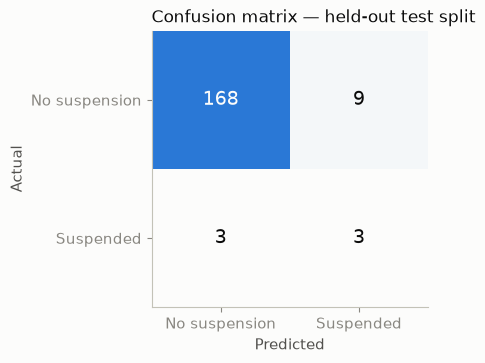

In [19]:
cm = metrics["confusion_matrix"]
labels = ["No suspension", "Suspended"]

seq_cmap = LinearSegmentedColormap.from_list("seq_blue", ["#fcfcfb", COLOR["blue"]])

fig, ax = plt.subplots(figsize=(4.5, 4.5))
im = ax.imshow(cm, cmap=seq_cmap)
ax.set_xticks([0, 1], labels)
ax.set_yticks([0, 1], labels)
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
for i in range(2):
    for j in range(2):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center", fontsize=14,
                color=SURFACE if cm[i, j] > cm.max() / 2 else INK["primary"])
ax.set_title("Confusion matrix — held-out test split", color=INK["primary"], loc="left", fontsize=12)
fig.tight_layout()
plt.show()


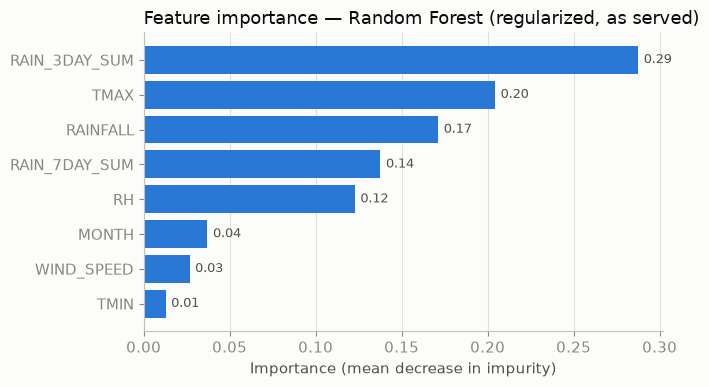

In [20]:
# Importances come from the model exactly as the API serves it: regularized RF
# fit on all 731 labeled days (app/ml_model.py -> get_model()).
served_model = reg_rf(random_state=42).fit(features[F], features.SUSPENDED)
importances = sm.feature_importance(served_model)

fig, ax = plt.subplots(figsize=(7, 4))
order_idx = importances.sort_values().index
bars = ax.barh(order_idx, importances.loc[order_idx], color=COLOR["blue"])
style(ax, ygrid=False)
ax.grid(axis="x", alpha=1)
ax.set_axisbelow(True)
for rect, val in zip(bars, importances.loc[order_idx]):
    ax.annotate(f"{val:.2f}", (rect.get_width(), rect.get_y() + rect.get_height() / 2),
                textcoords="offset points", xytext=(4, 0), va="center", color=INK["secondary"], fontsize=9)
ax.set_title("Feature importance — Random Forest (regularized, as served)", color=INK["primary"], loc="left", fontsize=13)
ax.set_xlabel("Importance (mean decrease in impurity)")
fig.tight_layout()
plt.show()

In [21]:
# Impurity importance can spread credit across correlated features (the three
# rainfall columns are strongly correlated). Permutation importance asks a more
# direct question: how much does F1 drop if one feature's values are shuffled?
from sklearn.inspection import permutation_importance

perm = permutation_importance(served_model, features[F], features.SUSPENDED,
                              scoring="f1", n_repeats=20, random_state=0)
importance_table = pd.DataFrame({
    "impurity_importance": importances,
    "permutation_importance_f1": pd.Series(perm.importances_mean, index=F),
}).sort_values("impurity_importance", ascending=False).round(3)
importance_table

,impurity_importance,permutation_importance_f1
RAIN_3DAY_SUM,0.288,0.484
TMAX,0.204,0.416
RAINFALL,0.171,0.185
RAIN_7DAY_SUM,0.138,-0.013
RH,0.123,0.020
MONTH,0.037,0.001
WIND_SPEED,0.027,-0.001
TMIN,0.013,0.008


The 3-day rolling rainfall sum is the single most important feature on both
measures. Maximum temperature ranks second — on rainy, overcast days the
daytime high stays low, so `TMAX` works as an indirect "it's a stormy day"
signal — followed by same-day rainfall. Once the 3-day sum is known, the
7-day sum adds almost nothing: its permutation importance is about zero.
Wind speed, minimum temperature, and month contribute little.

So the "accumulated wetness" reading holds for the **3-day** window, not
the 7-day one. (Permutation importance here is computed on the training data
itself, so treat it as a ranking, not a precise effect size.)

## 8. Overfitting check — train vs. test scores

In [22]:
all_models = {**sm.MODEL_FACTORIES, **sm.REGULARIZED_MODEL_FACTORIES}
diag = sm.train_vs_test_diagnostic(features, model_factories=all_models)
diag.round(3)

,model,train_accuracy,train_precision,train_recall,train_f1,test_accuracy,test_precision,test_recall,test_f1
0,Logistic Regression,0.929,0.309,0.944,0.466,0.902,0.227,0.833,0.357
1,Random Forest,1.000,1.000,1.000,1.000,0.956,0.333,0.333,0.333
2,Gradient Boosting,1.000,1.000,1.000,1.000,0.951,0.333,0.500,0.400
3,Random Forest (regularized),0.978,0.600,1.000,0.750,0.934,0.250,0.500,0.333
4,Gradient Boosting (regularized),0.978,0.600,1.000,0.750,0.918,0.200,0.500,0.286


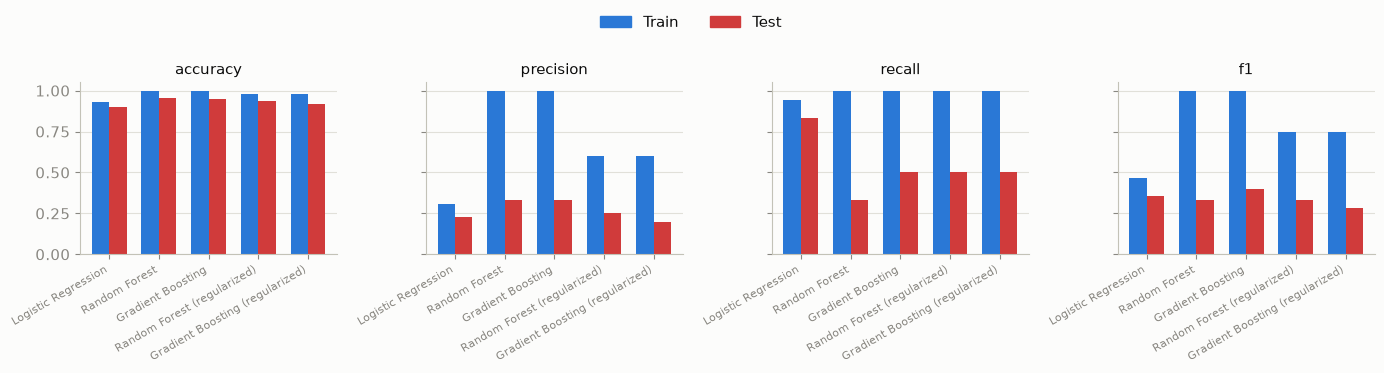

In [23]:
plot_metrics = ["accuracy", "precision", "recall", "f1"]
fig, axes = plt.subplots(1, len(plot_metrics), figsize=(14, 3.5), sharey=True)
x = np.arange(len(diag))
width = 0.35
for ax, m in zip(axes, plot_metrics):
    ax.bar(x - width/2, diag[f"train_{m}"], width, label="Train", color=COLOR["blue"])
    ax.bar(x + width/2, diag[f"test_{m}"], width, label="Test", color=STATUS["critical"])
    style(ax)
    ax.set_xticks(x, diag["model"], rotation=30, ha="right", fontsize=8)
    ax.set_title(m, fontsize=11, color=INK["primary"])
    ax.set_ylim(0, 1.05)
handles = [Patch(color=COLOR["blue"], label="Train"), Patch(color=STATUS["critical"], label="Test")]
fig.legend(handles=handles, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.08))
fig.suptitle("")
fig.tight_layout()
plt.show()


The unconstrained Random Forest and Gradient Boosting score a perfect 1.000 on
the training data and then drop sharply on the test data: they memorize the
~18 training positives instead of learning a general pattern. The regularized
variants no longer fit the training data perfectly (train F1 0.75), which is
the point of the `max_depth`/`min_samples_leaf` constraints. On this single
split, though, their test F1 is no better (0.333 and 0.286): with only 6
positive test days, one or two days flipping changes F1 a lot, so a single
split cannot separate these models. §9 compares them over many splits.

## 9. Cross-validation — is a single test split trustworthy?

With only ~6 positive test examples in one 75/25 split, a single held-out
score can swing a lot on which days happen to land in the test set.
5-fold stratified CV and leave-one-out CV both average over many splits to
give a steadier read.


In [24]:
cv = sm.cross_validate_models(features, model_factories=all_models)
cv_display = cv[["model", "accuracy_mean", "precision_mean", "recall_mean", "f1_mean",
                  "precision_std", "recall_std"]].round(3)
cv_display

,model,accuracy_mean,precision_mean,recall_mean,f1_mean,precision_std,recall_std
0,Logistic Regression,0.915,0.292,0.92,0.436,0.068,0.110
1,Random Forest,0.971,0.780,0.42,0.478,0.303,0.249
2,Gradient Boosting,0.951,0.308,0.43,0.343,0.066,0.244
3,Random Forest (regularized),0.959,0.457,0.76,0.560,0.179,0.261
4,Gradient Boosting (regularized),0.937,0.264,0.56,0.349,0.118,0.358


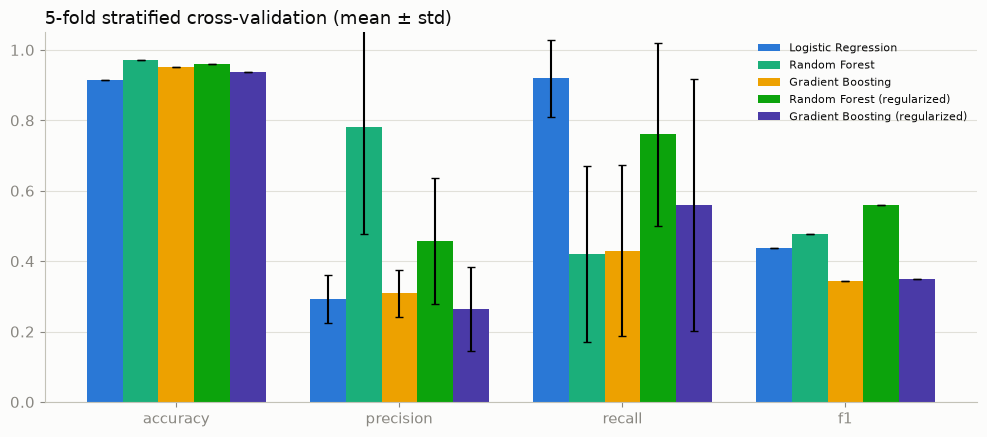

In [25]:
metrics_to_plot = ["accuracy_mean", "precision_mean", "recall_mean", "f1_mean"]
std_cols = {"precision_mean": "precision_std", "recall_mean": "recall_std"}
model_colors = [COLOR["blue"], COLOR["aqua"], COLOR["yellow"], STATUS["good"], COLOR["violet"]]

fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(metrics_to_plot))
width = 0.8 / len(cv)
for i, (_, row) in enumerate(cv.iterrows()):
    vals = [row[m] for m in metrics_to_plot]
    errs = [row[std_cols[m]] if m in std_cols else 0 for m in metrics_to_plot]
    ax.bar(x + (i - (len(cv) - 1) / 2) * width, vals, width, yerr=errs, capsize=3,
           label=row["model"], color=model_colors[i % len(model_colors)])
style(ax)
ax.set_xticks(x, [m.replace('_mean', '') for m in metrics_to_plot])
ax.set_ylim(0, 1.05)
ax.set_title("5-fold stratified cross-validation (mean ± std)", color=INK["primary"], loc="left", fontsize=13)
ax.legend(frameon=False, loc="upper right", fontsize=8)
fig.tight_layout()
plt.show()

In [26]:
loo = sm.leave_one_out_cv(features, model_factories=all_models)
loo.round(3)

,model,accuracy,precision,recall,f1
0,Logistic Regression,0.923,0.289,0.917,0.440
1,Random Forest,0.974,0.727,0.333,0.457
2,Gradient Boosting,0.958,0.387,0.500,0.436
3,Random Forest (regularized),0.959,0.429,0.750,0.545
4,Gradient Boosting (regularized),0.949,0.367,0.750,0.493


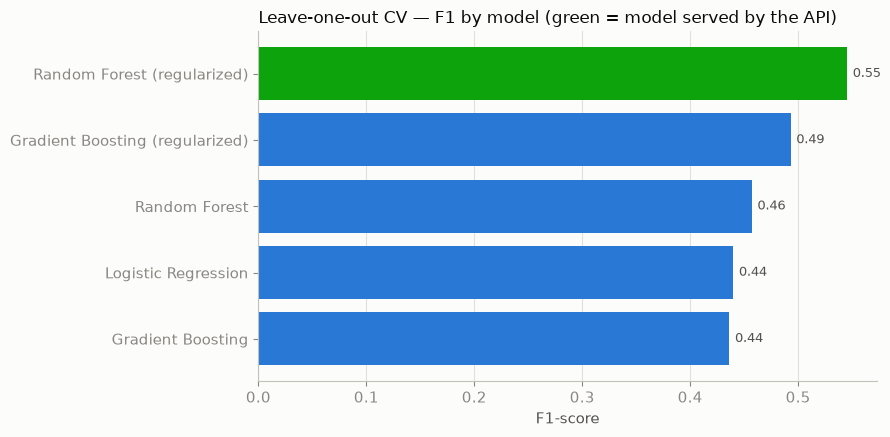

In [27]:
served = "Random Forest (regularized)"
loo_sorted = loo.sort_values("f1")
bar_colors = [STATUS["good"] if m == served else COLOR["blue"] for m in loo_sorted["model"]]

fig, ax = plt.subplots(figsize=(9, 4.5))
bars = ax.barh(loo_sorted["model"], loo_sorted["f1"], color=bar_colors)
style(ax, ygrid=False)
ax.grid(axis="x", alpha=1)
ax.set_axisbelow(True)
for rect, val in zip(bars, loo_sorted["f1"]):
    ax.annotate(f"{val:.2f}", (rect.get_width(), rect.get_y() + rect.get_height() / 2),
                textcoords="offset points", xytext=(4, 0), va="center", color=INK["secondary"], fontsize=9)
ax.set_title("Leave-one-out CV — F1 by model (green = model served by the API)",
             color=INK["primary"], loc="left", fontsize=12)
ax.set_xlabel("F1-score")
fig.tight_layout()
plt.show()


This is the comparison documented in `app/ml_model.py`'s docstring: the
regularized Random Forest has the best leave-one-out F1, which is why it's the
model actually promoted to serve `/v1/predictions`. The margin over the
regularized Gradient Boosting model is modest — both catch the same 18 of 24
suspension days; the Random Forest raises fewer false alarms (24 vs. 31).

### 9.1 Comparison with simple baselines

Two questions a skeptical reader should ask: does the model beat (a) always
answering "no suspension", and (b) a one-line rainfall rule? The rule's
threshold is tuned on 2023 and tested on 2024, and the regularized Random
Forest is evaluated on the same 2023 → 2024 split so the comparison is fair.

In [28]:
def score(y_true, y_hat):
    cm = confusion_matrix(y_true, y_hat, labels=[0, 1])
    return {
        "accuracy": accuracy_score(y_true, y_hat),
        "precision": precision_score(y_true, y_hat, zero_division=0),
        "recall": recall_score(y_true, y_hat, zero_division=0),
        "f1": f1_score(y_true, y_hat, zero_division=0),
        "TP": int(cm[1, 1]), "FP": int(cm[0, 1]), "FN": int(cm[1, 0]),
    }

X_all, y_all = features[F], features.SUSPENDED
is_2023 = (features.DATE.dt.year == 2023).to_numpy()
is_2024 = ~is_2023

baseline_rows = [{"method": "Always 'no suspension' (all 731 days)",
                  **score(y_all, np.zeros(len(y_all), dtype=int))}]
for col in ["RAINFALL", "RAIN_3DAY_SUM"]:
    candidates = np.unique(features.loc[is_2023, col])
    thr = max(candidates, key=lambda t: f1_score(y_all[is_2023], (features.loc[is_2023, col] >= t).astype(int)))
    baseline_rows.append({"method": f"Rule: {col} >= {thr:.1f} mm (tuned 2023, tested 2024)",
                          **score(y_all[is_2024], (features.loc[is_2024, col] >= thr).astype(int))})
rf_2023 = reg_rf(random_state=42).fit(X_all[is_2023], y_all[is_2023])
baseline_rows.append({"method": "Random Forest (regularized), trained 2023, tested 2024",
                      **score(y_all[is_2024], rf_2023.predict(X_all[is_2024]))})
pd.DataFrame(baseline_rows).round(3)

,method,accuracy,precision,recall,f1,TP,FP,FN
0,Always 'no suspension' (all 731 days),0.967,0.000,0.000,0.000,0,0,24
1,"Rule: RAINFALL >= 59.0 mm (tuned 2023, tested ...",0.962,0.438,0.583,0.500,7,9,5
2,"Rule: RAIN_3DAY_SUM >= 126.8 mm (tuned 2023, t...",0.951,0.364,0.667,0.471,8,14,4
3,"Random Forest (regularized), trained 2023, tes...",0.975,0.615,0.667,0.640,8,5,4


The always-"no suspension" baseline already scores 96.7% accuracy — higher
than any model here — which is why accuracy is not used to judge models in
this study. Against a single rainfall threshold, the regularized Random
Forest is better on the same 2024 test year, but by a few days, not by a
wide margin.

### 9.2 Time-aware validation

Suspensions come in runs of consecutive days during the same storm (e.g.
Aug 30 – Sep 5, 2023), and the rolling rainfall sums of neighbouring days are
nearly identical. Random splits (including LOO) can therefore put one day of
a storm in training and its neighbour in testing, which could make results
look better than they are. Two checks that keep each storm together:
training on one year and testing on the other, and leave-one-**month**-out CV
(24 folds).

In [29]:
def leave_one_month_out(X, y, dates, factory=reg_rf):
    groups = (dates.dt.year * 100 + dates.dt.month).to_numpy()
    X, y = np.asarray(X), np.asarray(y)
    pred = np.zeros_like(y)
    for g in np.unique(groups):
        te = groups == g
        pred[te] = factory(random_state=42).fit(X[~te], y[~te]).predict(X[te])
    return pred

rf_2024 = reg_rf(random_state=42).fit(X_all[is_2024], y_all[is_2024])
time_rows = [
    {"procedure": "Train 2023 -> test 2024", **score(y_all[is_2024], rf_2023.predict(X_all[is_2024]))},
    {"procedure": "Train 2024 -> test 2023", **score(y_all[is_2023], rf_2024.predict(X_all[is_2023]))},
    {"procedure": "Leave-one-month-out (24 folds)",
     **score(y_all, leave_one_month_out(X_all, y_all, features.DATE))},
]
pd.DataFrame(time_rows).round(3)

,procedure,accuracy,precision,recall,f1,TP,FP,FN
0,Train 2023 -> test 2024,0.975,0.615,0.667,0.640,8,5,4
1,Train 2024 -> test 2023,0.953,0.391,0.750,0.514,9,14,3
2,Leave-one-month-out (24 folds),0.960,0.439,0.750,0.554,18,23,6


The time-aware results land in the same range as the LOO estimate
(F1 ≈ 0.55), so splitting storms across train and test is not inflating the
headline number. The two single-year splits differ from each other (one year
is easier to predict than the other), which is another reminder that with
12 positive days per year, any single figure carries real uncertainty.

### 9.3 Using only information available the evening before

Most suspensions are announced the evening before (see the `Date Posted`
column in §4), when that day's rainfall total is not yet known. The model
above uses same-day rainfall, so it partly *explains* decisions after the
fact rather than *forecasting* them. To estimate how much that matters,
compare two rainfall-only models under leave-one-month-out CV: one with
same-day rainfall, one with rainfall only up to the previous day.

In [30]:
lagged = features[["DATE", "MONTH", "SUSPENDED"]].copy()
lagged["RAIN_PREV_DAY"] = features.RAINFALL.shift(1).fillna(0)
lagged["RAIN_PREV_3DAY_SUM"] = features.RAINFALL.shift(1).rolling(3, min_periods=1).sum().fillna(0)
lagged["RAIN_PREV_7DAY_SUM"] = features.RAINFALL.shift(1).rolling(7, min_periods=1).sum().fillna(0)

SAME_DAY_RAIN = ["RAINFALL", "RAIN_3DAY_SUM", "RAIN_7DAY_SUM", "MONTH"]
PREV_DAY_RAIN = ["RAIN_PREV_DAY", "RAIN_PREV_3DAY_SUM", "RAIN_PREV_7DAY_SUM", "MONTH"]
pd.DataFrame([
    {"features": "Rainfall incl. same day (4 features)",
     **score(y_all, leave_one_month_out(features[SAME_DAY_RAIN], y_all, features.DATE))},
    {"features": "Rainfall up to previous day only (4 features)",
     **score(y_all, leave_one_month_out(lagged[PREV_DAY_RAIN], y_all, features.DATE))},
]).round(3)

,features,accuracy,precision,recall,f1,TP,FP,FN
0,Rainfall incl. same day (4 features),0.953,0.391,0.750,0.514,18,28,6
1,Rainfall up to previous day only (4 features),0.944,0.333,0.708,0.453,17,34,7


Dropping same-day rainfall costs some F1 but does not erase the signal.
A version of this model meant to *forecast* suspensions would need forecast
rainfall (e.g., PAGASA's rainfall outlook) in place of same-day observations.

## 10. Example predictions

In [31]:
# Same model the API serves: regularized RF fit on all 731 labeled days.
examples = [
    dict(rainfall=150, tmax=28, tmin=24, rh=92, wind_speed=6, month=8, rain_3day_sum=300, rain_7day_sum=400,
         scenario="Sustained heavy rain, several wet days prior"),
    dict(rainfall=5, tmax=31, tmin=23, rh=60, wind_speed=4, month=3, rain_3day_sum=5, rain_7day_sum=10,
         scenario="Ordinary dry-season day"),
    dict(rainfall=40, tmax=28, tmin=24, rh=85, wind_speed=5, month=9, rain_3day_sum=70, rain_7day_sum=90,
         scenario="Moderate rain, wet week"),
]

rows = []
for ex in examples:
    scenario = ex.pop("scenario")
    label, proba = sm.suggest_suspension(served_model, **ex)
    rows.append({"scenario": scenario, **ex, "probability": round(proba, 2), "recommendation": label})

pd.DataFrame(rows)

,scenario,rainfall,tmax,tmin,rh,wind_speed,month,rain_3day_sum,rain_7day_sum,probability,recommendation
0,"Sustained heavy rain, several wet days prior",150,28,24,92,6,8,300,400,0.87,Suspension Likely — recommend monitoring PAGAS...
1,Ordinary dry-season day,5,31,23,60,4,3,5,10,0.00,No Suspension Likely — normal conditions
2,"Moderate rain, wet week",40,28,24,85,5,9,70,90,0.30,No Suspension Likely — normal conditions


The model clearly separates the high-risk scenario (p = 0.87) from an
ordinary dry day (p = 0.00). The moderate-rain scenario lands just below the
0.30 "Elevated Risk" cutoff (shown rounded as 0.30), so it is still labeled
"No Suspension Likely" — but only barely: 40 mm on a wet week is close to
the point where the model starts recommending closer monitoring.

## 11. Supplementary validation: real 2025 rainfall vs. the actual suspension log

Everything above trains and evaluates on 2023–2024, where negative labels rest on
an assumption (an unlisted date *probably* had no suspension) because the 2025
suspension dates had no matching weather row at all — they were dropped entirely
from the earlier analysis (see the "dropped" table in §5).

`SBIA Rainfall 2025.csv` (parsed from the official PAGASA Form 4002-A summary for
the SBIA station) closes part of that gap: **complete, real daily rainfall for
all 365 days of 2025** — the same year almost every scraped suspension record
falls in. Temperature, humidity, and wind are not available for 2025, so this
section is deliberately scoped to a **rainfall-only validation**, not a rebuild of
the main 8-feature model. The question it answers: *using only real 2025
rainfall, does the rainfall–suspension relationship found in 2023–2024 actually
hold up on a different year's genuine data?*


In [32]:
rain2025 = pd.read_csv("SBIA Rainfall 2025.csv")
rain2025["DATE"] = pd.to_datetime(dict(year=rain2025.YEAR, month=rain2025.MONTH, day=rain2025.DAY))
rain2025 = rain2025.sort_values("DATE").reset_index(drop=True)
rain2025["RAIN_3DAY_SUM"] = rain2025.RAINFALL.rolling(3, min_periods=1).sum()
rain2025["RAIN_7DAY_SUM"] = rain2025.RAINFALL.rolling(7, min_periods=1).sum()
rain2025["MONTH"] = rain2025.DATE.dt.month
rain2025["RAIN_CATEGORY"] = rain2025.RAINFALL.map(eda.rain_category)

susp_dates_all = set(sm.load_suspensions().loc[lambda d: d["Suspension Decision"] == 1, "Date"])
rain2025["SUSPENDED"] = rain2025["DATE"].isin(susp_dates_all).astype(int)

print(f"{len(rain2025)} days, {rain2025.SUSPENDED.sum()} suspended "
      f"({rain2025.SUSPENDED.mean():.1%}) -- every one of these suspension dates "
      f"now has a real (not assumed) rainfall reading.")
rain2025.SUSPENDED.value_counts().rename({0: "No Suspension", 1: "Suspended"}).to_frame("days")


365 days, 19 suspended (5.2%) -- every one of these suspension dates now has a real (not assumed) rainfall reading.


,days
SUSPENDED,
No Suspension,346
Suspended,19


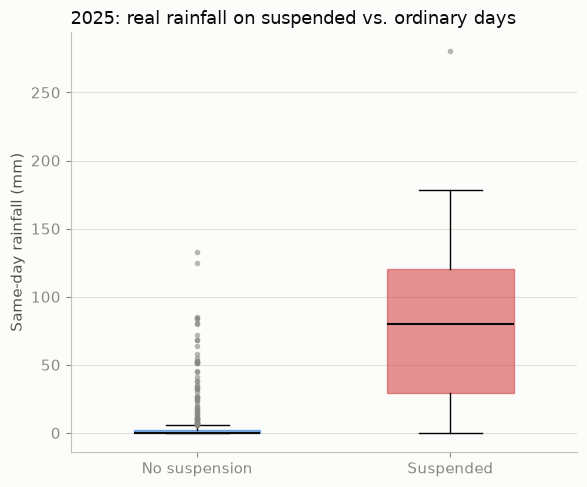

In [33]:
fig, ax = plt.subplots(figsize=(6, 5))
groups = [rain2025.loc[rain2025.SUSPENDED == 0, "RAINFALL"], rain2025.loc[rain2025.SUSPENDED == 1, "RAINFALL"]]
bp = ax.boxplot(groups, tick_labels=["No suspension", "Suspended"], patch_artist=True, widths=0.5,
                 medianprops=dict(color=INK["primary"], linewidth=1.5),
                 flierprops=dict(markerfacecolor=INK["muted"], markeredgecolor="none", markersize=4, alpha=0.6))
for patch, c in zip(bp["boxes"], [COLOR["blue"], STATUS["critical"]]):
    patch.set_facecolor(c)
    patch.set_alpha(0.55)
    patch.set_edgecolor(c)
style(ax)
ax.set_ylabel("Same-day rainfall (mm)")
ax.set_title("2025: real rainfall on suspended vs. ordinary days", color=INK["primary"], loc="left", fontsize=13)
fig.tight_layout()
plt.show()


Suspended 2025 days average **86mm** of same-day rainfall vs. **6.9mm** on ordinary
days -- and the gap is even wider on the rolling sums (241mm vs. 22mm 3-day average;
400mm vs. 60mm 7-day average). This is the same pattern seen in 2023–2024, now on
a year that played no part in building the main model.

In [34]:
order = ["none", "light", "moderate", "heavy", "intense", "torrential"]
ct = pd.crosstab(rain2025["RAIN_CATEGORY"], rain2025["SUSPENDED"]).reindex(order).fillna(0).astype(int)
ct.columns = ["No Suspension", "Suspended"]
ct


,No Suspension,Suspended
RAIN_CATEGORY,,
none,287,4
light,15,1
moderate,14,0
heavy,20,3
intense,10,10
torrential,0,1


14 of the 19 real suspension days (74%) fall in the "heavy" category or worse, and
10 alone are "intense" (65–185mm). But 4 suspension days show **no** meaningful
same-day rain -- checking those specifically:


In [35]:
no_rain_suspended = rain2025.loc[(rain2025.SUSPENDED == 1) & (rain2025.RAIN_CATEGORY == "none"),
                                  ["DATE", "RAINFALL", "RAIN_3DAY_SUM", "RAIN_7DAY_SUM"]]
no_rain_suspended


,DATE,RAINFALL,RAIN_3DAY_SUM,RAIN_7DAY_SUM
267,2025-09-25,2.5,143.9,284.7
268,2025-09-26,4.5,54.9,281.6
292,2025-10-20,0.0,75.9,77.6
314,2025-11-11,1.6,130.7,132.3


Every one of these had substantial *rolling* rainfall (55–144mm over the prior 3
days, 78–285mm over the prior 7) despite little rain that specific day. The
PAGASA summary's weather-system column also shows that each of them was a
typhoon day, or the day after one: Typhoon Opong (Sep 25–26), the day after
Tropical Storm Ramil (Oct 20), and Typhoon Uwan (Nov 11, a national directive).
So these are partly **pre-emptive, storm-driven** suspensions — decided on
forecasts and storm signals — rather than purely rainfall-driven ones. That is
a kind of suspension a model built only on observed daily weather cannot fully
capture.

In [36]:
# True out-of-sample test: train the rainfall-only regularized RF on 2023–2024
# ONLY, then predict every day of 2025. No 2025 data is used for training.
RAIN_ONLY_COLS = ["RAINFALL", "RAIN_3DAY_SUM", "RAIN_7DAY_SUM", "MONTH"]
rain_model = reg_rf(random_state=42).fit(features[RAIN_ONLY_COLS], features.SUSPENDED)
pred_2025 = rain_model.predict(rain2025[RAIN_ONLY_COLS])

external = pd.DataFrame([{"evaluation": "Trained on 2023–2024, tested on all of 2025",
                          **score(rain2025.SUSPENDED, pred_2025)}]).round(3)
missed = rain2025.loc[(rain2025.SUSPENDED == 1) & (pred_2025 == 0), "DATE"].dt.date.tolist()
print("Missed 2025 suspension days:", missed)
external

Missed 2025 suspension days: [datetime.date(2025, 9, 25), datetime.date(2025, 9, 26), datetime.date(2025, 10, 20), datetime.date(2025, 11, 11)]


,evaluation,accuracy,precision,recall,f1,TP,FP,FN
0,"Trained on 2023–2024, tested on all of 2025",0.956,0.556,0.789,0.652,15,12,4


In [37]:
# Secondary check (NOT out-of-sample): leave-one-out within 2025 itself, so the
# model is retrained on the other 364 days of 2025 for each prediction.
factory = {"Random Forest (regularized, rainfall-only)": reg_rf}
loo_2025 = sm.leave_one_out_cv(rain2025, model_factories=factory, feature_cols=RAIN_ONLY_COLS)
loo_2025.round(3)

,model,accuracy,precision,recall,f1
0,"Random Forest (regularized, rainfall-only)",0.951,0.515,0.895,0.654


**The out-of-sample result is the one to cite.** A rainfall-only regularized
Random Forest trained only on 2023–2024 and then applied to all of 2025 catches
**15 of the 19** real suspension days, with **12 false alarms** out of 346
ordinary days (precision 0.556, recall 0.789, F1 0.652). The 4 days it misses
are exactly the storm-driven, low-rainfall days discussed above.

The second table retrains within 2025 (leave-one-out: 17 of 19 caught, 16
false alarms), so it measures how learnable 2025 is on its own — it is
**not** a test on unseen data and should not be described as one.

Caveats: 2025 has a higher suspension rate (5.2% vs. 3.3%), only rainfall is
available for that year, and the 2025 suspension log covers July–November, so
"unlisted day = no suspension" is still an assumption for 2025 as well.

**What this does and doesn't resolve:** the negative-labeling assumption itself is
unchanged -- the suspension log still only records days a suspension *was*
declared, in 2025 as in 2023–2024, so "unlisted day = no suspension" is still an
assumption here too. What's new is that, for 2025, the rainfall side of that
assumption is no longer inferred or unavailable -- it's real, complete, matched
1:1 with every suspension date. That is a meaningful reduction in this study's
biggest documented limitation, and a natural next step (not undertaken here) would
be sourcing 2025 temperature/humidity/wind to re-run the full 8-feature model on
this same real window.


## Summary & limitations

- **Rainfall drives the signal.** The 3-day rolling rainfall sum is the most
  important feature of the served model, followed by maximum temperature (a
  proxy for overcast, stormy days) and same-day rainfall. The 7-day sum adds
  little once the 3-day sum is known.
- **The dataset is small and imbalanced** (24 suspended days out of 731 in
  the 2023–2024 window), and the negative labels rest on an assumption
  (unlisted dates = no suspension) rather than a confirmed complete record.
  Metrics should be read as a proof-of-concept benchmark.
- **The regularized Random Forest** (`max_depth=4, min_samples_leaf=4`) is
  the model actually served by the API. It has the best leave-one-out F1
  (0.545), its results hold under time-aware validation (§9.2), and it
  beats a single rainfall threshold, though by a modest margin (§9.1).
  Its accuracy (≈ 0.96) is *below* the 0.967 of always predicting "no
  suspension", so accuracy is not evidence of skill here.
- **Real 2025 rainfall confirms the core finding out of sample (§11):** a
  rainfall-only model trained on 2023–2024 catches 15 of 19 2025 suspension
  days (12 false alarms out of 346 ordinary days).
  The misses are typhoon-driven, pre-emptive suspensions with little same-day
  rain.
- **Known limitations:** same-day rainfall is not known when most
  suspensions are announced (§9.3); the log likely misses some suspension
  days (e.g., 2023-07-27, 168 mm, between two logged suspension days) and
  mixes weekend days in both classes; storm signals are not a model feature.
- **Next steps:** restrict the dataset to school days, verify suspicious
  heavy-rain "negative" days against the city's announcements, add a
  tropical-cyclone indicator, and source 2025 temperature/humidity/wind to
  re-run the full 8-feature model on a genuinely overlapping window.